In [16]:
import numpy as np 
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt 

In [17]:
exoplanets_df = pd.read_csv("exoplanet_data.csv", comment="#")
exoplanets_df.head()
# 5 rows, 92 columns

,pl_name,hostname,default_flag,sy_snum,sy_pnum,discoverymethod,disc_year,disc_facility,soltype,pl_controv_flag,...,sy_vmagerr2,sy_kmag,sy_kmagerr1,sy_kmagerr2,sy_gaiamag,sy_gaiamagerr1,sy_gaiamagerr2,rowupdate,pl_pubdate,releasedate
0,7 CMa c,7 CMa,0,1,2,Radial Velocity,2019,Multiple Observatories,Published Confirmed,0,...,-0.03,1.564,0.252,-0.252,3.67853,0.004135,-0.004135,2024-09-13,2024-07,2024-09-13
1,7 CMa c,7 CMa,1,1,2,Radial Velocity,2019,Multiple Observatories,Published Confirmed,0,...,-0.03,1.564,0.252,-0.252,3.67853,0.004135,-0.004135,2019-10-18,2019-11,2019-10-24
2,DMPP-1 b,DMPP-1,1,1,4,Radial Velocity,2019,La Silla Observatory,Published Confirmed,0,...,-0.03,6.690,0.024,-0.024,7.85032,0.000290,-0.000290,2026-03-05,2026-04,2026-03-05
3,DMPP-1 b,DMPP-1,0,1,4,Radial Velocity,2019,La Silla Observatory,Published Confirmed,0,...,-0.03,6.690,0.024,-0.024,7.85032,0.000290,-0.000290,2020-01-23,2019-12,2020-01-30
4,DMPP-1 c,DMPP-1,0,1,4,Radial Velocity,2019,La Silla Observatory,Published Confirmed,0,...,-0.03,6.690,0.024,-0.024,7.85032,0.000290,-0.000290,2020-01-23,2019-12,2020-01-30


In [6]:
print(exoplanets_df.columns.tolist())
# idk what bmassprov, radjlim, gaiamag, and other stuff is 

['pl_name', 'hostname', 'default_flag', 'sy_snum', 'sy_pnum', 'discoverymethod', 'disc_year', 'disc_facility', 'soltype', 'pl_controv_flag', 'pl_refname', 'pl_orbper', 'pl_orbpererr1', 'pl_orbpererr2', 'pl_orbperlim', 'pl_orbsmax', 'pl_orbsmaxerr1', 'pl_orbsmaxerr2', 'pl_orbsmaxlim', 'pl_rade', 'pl_radeerr1', 'pl_radeerr2', 'pl_radelim', 'pl_radj', 'pl_radjerr1', 'pl_radjerr2', 'pl_radjlim', 'pl_bmasse', 'pl_bmasseerr1', 'pl_bmasseerr2', 'pl_bmasselim', 'pl_bmassj', 'pl_bmassjerr1', 'pl_bmassjerr2', 'pl_bmassjlim', 'pl_bmassprov', 'pl_orbeccen', 'pl_orbeccenerr1', 'pl_orbeccenerr2', 'pl_orbeccenlim', 'pl_insol', 'pl_insolerr1', 'pl_insolerr2', 'pl_insollim', 'pl_eqt', 'pl_eqterr1', 'pl_eqterr2', 'pl_eqtlim', 'ttv_flag', 'st_refname', 'st_spectype', 'st_teff', 'st_tefferr1', 'st_tefferr2', 'st_tefflim', 'st_rad', 'st_raderr1', 'st_raderr2', 'st_radlim', 'st_mass', 'st_masserr1', 'st_masserr2', 'st_masslim', 'st_met', 'st_meterr1', 'st_meterr2', 'st_metlim', 'st_metratio', 'st_logg', 'st

In [7]:
# # 1. Table Label: Planet Name = pl_name --> gives planet name

# 2. Table Label: Host Name = hostname --> gives hostname of star 

# 3. Table Label: Discovery Method = discoverymethod --> gives how it was discovered

# 4. Table Label: Spectral Type = st_spectype --> gives type of star

# 5. Table Label: Equilibrium Temperature [K] = pl_eqt --> gives temp of planet 

# 6. Table Label: Planet Mass or Mass*sin(i) [Jupiter Mass] = pl_bmassj --> best planet mass estimate given jupiter mass 

In [8]:
selected_columns = [
    "pl_name",
    "hostname",
    "discoverymethod",
    "st_spectype",
    "pl_eqt",
    "pl_bmassj"
]

small_exoplanets_df = exoplanets_df[selected_columns]
small_exoplanets_df.head()

,pl_name,hostname,discoverymethod,st_spectype,pl_eqt,pl_bmassj
0,7 CMa c,7 CMa,Radial Velocity,NaN,NaN,0.912000
1,7 CMa c,7 CMa,Radial Velocity,NaN,NaN,0.870000
2,DMPP-1 b,DMPP-1,Radial Velocity,NaN,NaN,0.052859
3,DMPP-1 b,DMPP-1,Radial Velocity,F8 V,877.0,0.076362
4,DMPP-1 c,DMPP-1,Radial Velocity,F8 V,1239.0,0.030205


In [9]:
clean_exoplanets_df = small_exoplanets_df.dropna()
clean_exoplanets_df.head()

,pl_name,hostname,discoverymethod,st_spectype,pl_eqt,pl_bmassj
3,DMPP-1 b,DMPP-1,Radial Velocity,F8 V,877.0,0.076362
4,DMPP-1 c,DMPP-1,Radial Velocity,F8 V,1239.0,0.030205
6,DMPP-1 d,DMPP-1,Radial Velocity,F8 V,1632.0,0.010540
8,DMPP-1 e,DMPP-1,Radial Velocity,F8 V,1314.0,0.012994
9,DMPP-2 b,DMPP-2,Radial Velocity,F5 V,1000.0,0.437000


In [11]:
print(clean_exoplanets_df.shape)
# smaller in terms of columns but an added row 

(77, 6)


In [12]:
display(clean_exoplanets_df.head())
display(clean_exoplanets_df.tail())
print(clean_exoplanets_df.columns.tolist())

,pl_name,hostname,discoverymethod,st_spectype,pl_eqt,pl_bmassj
3,DMPP-1 b,DMPP-1,Radial Velocity,F8 V,877.0,0.076362
4,DMPP-1 c,DMPP-1,Radial Velocity,F8 V,1239.0,0.030205
6,DMPP-1 d,DMPP-1,Radial Velocity,F8 V,1632.0,0.010540
8,DMPP-1 e,DMPP-1,Radial Velocity,F8 V,1314.0,0.012994
9,DMPP-2 b,DMPP-2,Radial Velocity,F5 V,1000.0,0.437000


,pl_name,hostname,discoverymethod,st_spectype,pl_eqt,pl_bmassj
575,WASP-185 b,WASP-185,Transit,G0 V,1160.0,0.980
580,WASP-190 b,WASP-190,Transit,F6 IV-V,1500.0,1.000
584,WASP-192 b,WASP-192,Transit,G0 V,1620.0,2.300
585,XO-7 b,XO-7,Transit,G0 V,1743.0,0.709
597,eps Ind A b,eps Ind A,Radial Velocity,K5 V,275.0,6.310


['pl_name', 'hostname', 'discoverymethod', 'st_spectype', 'pl_eqt', 'pl_bmassj']


In [13]:
method_counts = clean_exoplanets_df["discoverymethod"].value_counts()
print(method_counts)

discoverymethod
Transit            62
Radial Velocity    13
Imaging             2
Name: count, dtype: int64


In [14]:
# types of discovery methods = transit, radial velocity, imaging, etc. 
# number next to it says how many there are of each 
# transit has the most and imaging has the least 

# Transit =  measure tiny regular dips in a star's brightness when a planet passes directly in front of it from our point of view
# Radial Velocity = detect a slight wobble in a star's motion by measuring shifts in its light spectrum
# Imaging = block out the overwhelming glare of a host star to capture an actual picture or direct light measurement of planet orbiting it

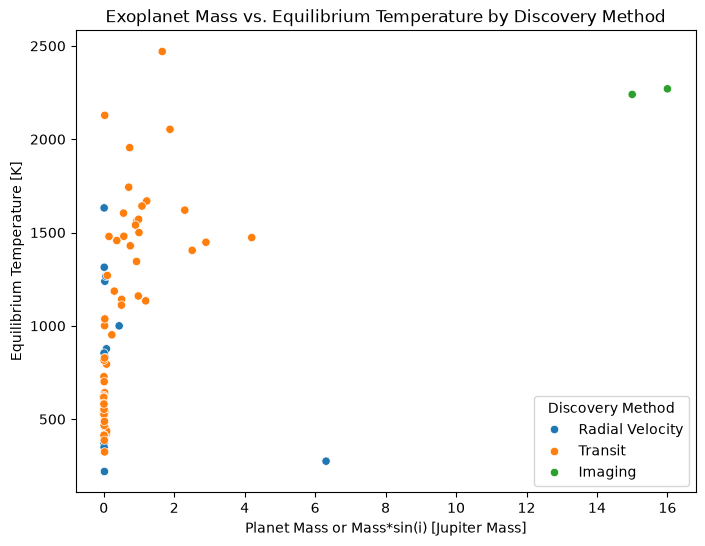

In [18]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=clean_exoplanets_df,
    x="pl_bmassj",
    y="pl_eqt",
    hue="discoverymethod"
)

plt.title("Exoplanet Mass vs. Equilibrium Temperature by Discovery Method")
plt.xlabel("Planet Mass or Mass*sin(i) [Jupiter Mass]")
plt.ylabel("Equilibrium Temperature [K]")
plt.legend(title="Discovery Method")

plt.show()

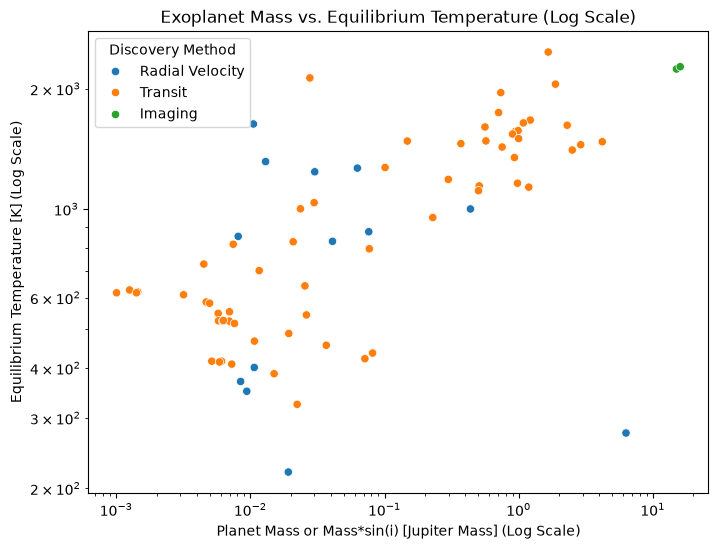

In [19]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=clean_exoplanets_df,
    x="pl_bmassj",
    y="pl_eqt",
    hue="discoverymethod"
)

plt.xscale("log")
plt.yscale("log")

plt.title("Exoplanet Mass vs. Equilibrium Temperature (Log Scale)")
plt.xlabel("Planet Mass or Mass*sin(i) [Jupiter Mass] (Log Scale)")
plt.ylabel("Equilibrium Temperature [K] (Log Scale)")
plt.legend(title="Discovery Method")

plt.show()

In [20]:
# exoplants found by imaging are more likely to be BIG 

In [21]:
# Filter for planets with mass larger than 5 Jupiter masses
massive_planets = clean_exoplanets_df[clean_exoplanets_df["pl_bmassj"] > 5]
coldest_massive_planet = massive_planets.loc[massive_planets["pl_eqt"].idxmin()]
print(coldest_massive_planet)

pl_name                eps Ind A b
hostname                 eps Ind A
discoverymethod    Radial Velocity
st_spectype                   K5 V
pl_eqt                       275.0
pl_bmassj                     6.31
Name: 597, dtype: object


In [22]:
massive_planets = clean_exoplanets_df[clean_exoplanets_df["pl_bmassj"] > 5]
coldest_idx = massive_planets["pl_eqt"].idxmin()
print("Row Index:", coldest_idx)

display(clean_exoplanets_df.loc[[coldest_idx]])

Row Index: 597


,pl_name,hostname,discoverymethod,st_spectype,pl_eqt,pl_bmassj
597,eps Ind A b,eps Ind A,Radial Velocity,K5 V,275.0,6.31


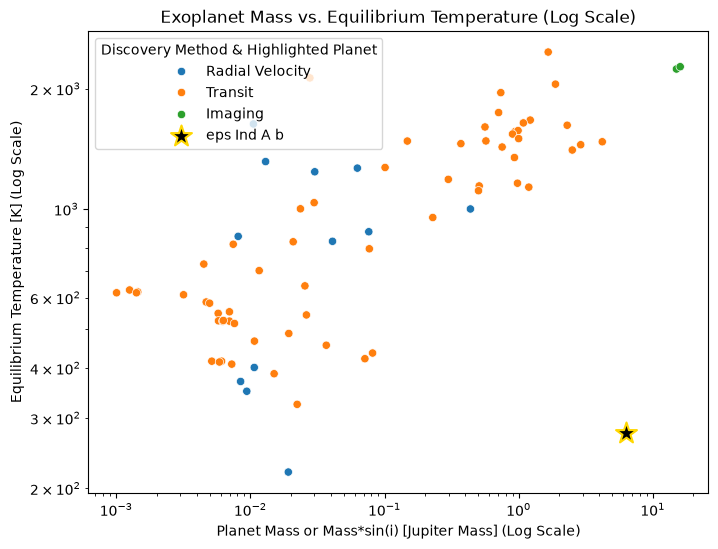

In [23]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=clean_exoplanets_df,
    x="pl_bmassj",
    y="pl_eqt",
    hue="discoverymethod"
)

plt.scatter(
    x=coldest_massive_planet["pl_bmassj"],
    y=coldest_massive_planet["pl_eqt"],
    color="black",
    marker="*",
    s=250,
    edgecolor="gold",
    linewidth=1.5,
    zorder=5,
    label=coldest_massive_planet["pl_name"]
)

plt.xscale("log")
plt.yscale("log")

plt.title("Exoplanet Mass vs. Equilibrium Temperature (Log Scale)")
plt.xlabel("Planet Mass or Mass*sin(i) [Jupiter Mass] (Log Scale)")
plt.ylabel("Equilibrium Temperature [K] (Log Scale)")
plt.legend(title="Discovery Method & Highlighted Planet")

plt.show()

In [24]:
# Title = A temperate super-Jupiter imaged with JWST in the mid-infrared
# until now, every exoplanet ever directly photographed was very young --> even tho earlier wobble measurements hinted a planet was there... JWST showed its actual orbit and properties are very different from what scientists previously thought
# yes it matches 
# its rhe coldest exoplanet ever directly photographed 
# yeah it matches them exactly 